# Experiment 035: matched GRPO analysis at 3B

Together, the memory pilots, the stopped full-parameter arm and completed matched LoRA control. It compares feasibility, training behaviour and the available endpoint results.

In [7]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / 'config.py').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from analysis.stats import align_pred_rows, mcnemar_exact, paired_delta_ci

RES = ROOT / 'results'
FIG = ROOT / 'analysis' / 'figures' / '035_4'
FIG.mkdir(parents=True, exist_ok=True)

def jload(path):
    with open(path) as handle:
        return json.load(handle)


def read_jsonl(path):
    with open(path) as handle:
        return [json.loads(line) for line in handle if line.strip()]


def accuracy(rows):
    return float(np.mean([row['correct'] for row in rows]))


def grouped_accuracy(metrics):
    return [
        metrics['overall'],
        metrics['per_tier_acc']['easy'],
        metrics['per_tier_acc']['medium'],
        metrics['per_tier_acc']['hard'],
    ]


def save(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=300, bbox_inches='tight')

FULL = RES / '035_COLAB_FULL_B3_matched_full_grpo_seed0'
LORA = RES / '035_COLAB_FULL_B3_matched_lora_grpo_seed0'
START = RES / '035_start_B3_seed0'
HIST = RES / '003_COLAB_FULL_B3_sft_grpo_seed0'
PILOTS = RES / '035_technical' / 'pilots' / 'B3'

start_probe = jload(START / 'start_logprob.json')
lora_probe = jload(LORA / 'grpo_logprob.json')
lora_eval = jload(LORA / 'grpo_eval.json')
hist_probe = jload(HIST / 'grpo_logprob.json')
hist_eval = jload(HIST / 'grpo_eval.json')

start_probe_rows = read_jsonl(START / 'start_logprob_preds.jsonl')
lora_probe_rows = read_jsonl(LORA / 'grpo_logprob_preds.jsonl')
lora_eval_rows = read_jsonl(LORA / 'grpo_preds.jsonl')
hist_probe_rows = read_jsonl(HIST / 'grpo_logprob_preds.jsonl')
hist_eval_rows = read_jsonl(HIST / 'grpo_preds.jsonl')

for metrics, rows in [
    (start_probe, start_probe_rows),
    (lora_probe, lora_probe_rows),
    (lora_eval, lora_eval_rows),
    (hist_probe, hist_probe_rows),
    (hist_eval, hist_eval_rows),
]:
    metrics['overall'] = accuracy(rows)

lora_log = pd.DataFrame(jload(LORA / 'grpo_trainlog.json'))
lora_log = lora_log[lora_log['step'].notna() & lora_log['reward'].notna()].copy()
full_status = jload(FULL / 'worker_status.json')
lora_status = jload(LORA / 'worker_status.json')

plt.style.use('seaborn-v0_8-whitegrid')
print('figures ->', FIG.relative_to(ROOT))

figures -> analysis/figures/035_4


## Run outcomes and memory

,run,outcome,updates,peak_reserved_gib,wall_minutes
0,pilot A,OOM,0,78.72,3.2
1,pilot B,OOM,0,78.70,1.7
2,pilot C,passed,30,72.20,13.6
3,pilot A_GC,passed,30,67.22,8.9
4,full A_GC,A1 stop,50,67.21,23.7
5,LoRA A_GC,completed,500,24.12,213.7


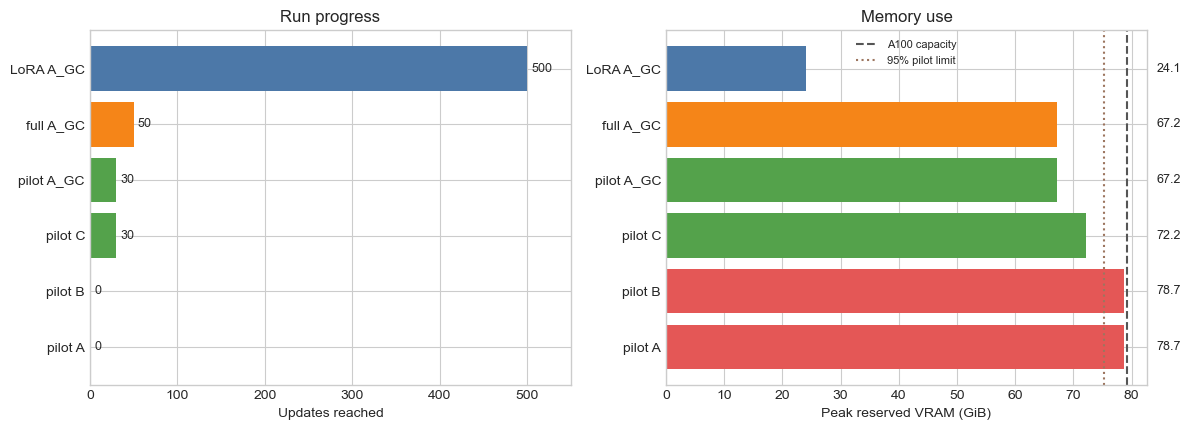

In [8]:
pilot_rows = []
for rung in ('A', 'B', 'C', 'A_GC'):
    report = jload(PILOTS / rung / 'pilot_report.json')
    pilot_rows.append({
        'run': f'pilot {rung}',
        'outcome': 'passed' if report['passed'] else 'OOM',
        'updates': int(report.get('end_step', 0)),
        'peak_reserved_gib': report['peak_reserved_gib'],
        'wall_minutes': report['wall_seconds'] / 60,
    })

outcomes = pd.DataFrame(pilot_rows + [
    {
        'run': 'full A_GC',
        'outcome': 'A1 stop',
        'updates': 50,
        'peak_reserved_gib': full_status['peak_reserved_gib'],
        'wall_minutes': full_status['wall_seconds'] / 60,
    },
    {
        'run': 'LoRA A_GC',
        'outcome': 'completed',
        'updates': int(lora_status['end_step']),
        'peak_reserved_gib': lora_status['peak_reserved_gib'],
        'wall_minutes': lora_status['wall_seconds'] / 60,
    },
])

display(outcomes.round({'peak_reserved_gib': 2, 'wall_minutes': 1}))

colors = outcomes['outcome'].map({
    'passed': '#54A24B', 'OOM': '#E45756', 'A1 stop': '#F58518', 'completed': '#4C78A8'
})
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].barh(outcomes['run'], outcomes['updates'], color=colors)
axes[0].margins(x=0.10)
axes[0].set_xlabel('Updates reached')
axes[0].set_title('Run progress')
for i, value in enumerate(outcomes['updates']):
    axes[0].text(value + 5, i, str(value), va='center', fontsize=9)

axes[1].barh(outcomes['run'], outcomes['peak_reserved_gib'], color=colors)
axes[1].axvline(79.25, color='#555555', linestyle='--', label='A100 capacity')
axes[1].axvline(79.25 * 0.95, color='#9C755F', linestyle=':', label='95% pilot limit')
axes[1].set_xlabel('Peak reserved VRAM (GiB)')
axes[1].set_title('Memory use')
axes[1].legend(fontsize=8)
for i, value in enumerate(outcomes['peak_reserved_gib']):
    axes[1].text(1.02, i, f'{value:.1f}', transform=axes[1].get_yaxis_transform(),
                 va='center', fontsize=9)

fig.tight_layout()
save(fig, 'run_outcomes_memory')
plt.show()

## LoRA training dynamics

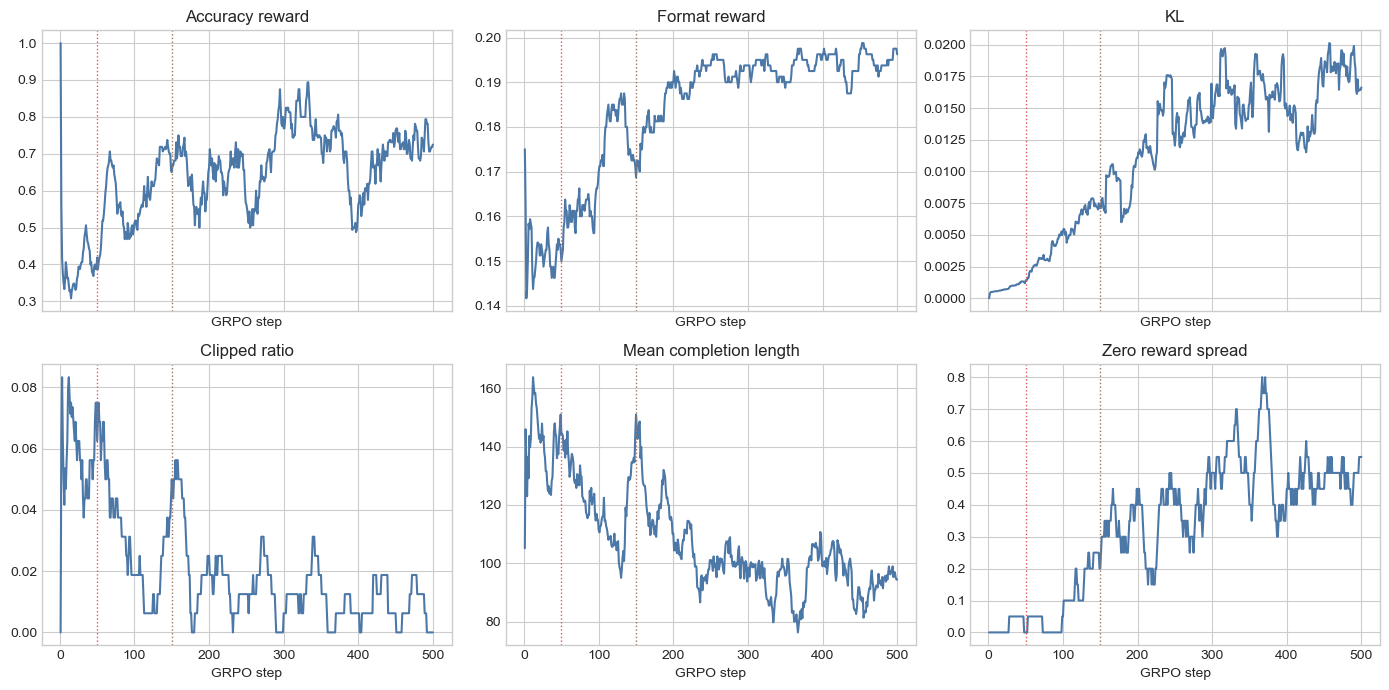

In [9]:
series = [
    ('rewards/accuracy_reward/mean', 'Accuracy reward'),
    ('rewards/format_reward/mean', 'Format reward'),
    ('kl', 'KL'),
    ('completions/clipped_ratio', 'Clipped ratio'),
    ('completions/mean_length', 'Mean completion length'),
    ('frac_reward_zero_std', 'Zero reward spread'),
]

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for ax, (column, title) in zip(axes.flat, series):
    ax.plot(lora_log['step'], lora_log[column].rolling(20, min_periods=1).mean(), color='#4C78A8')
    ax.axvline(50, color='#E45756', linestyle=':', linewidth=1)
    ax.axvline(150, color='#9C755F', linestyle=':', linewidth=1)
    ax.set_title(title)
    ax.set_xlabel('GRPO step')
fig.tight_layout()
save(fig, 'lora_training_dynamics')
plt.show()

## Full and LoRA near step 50

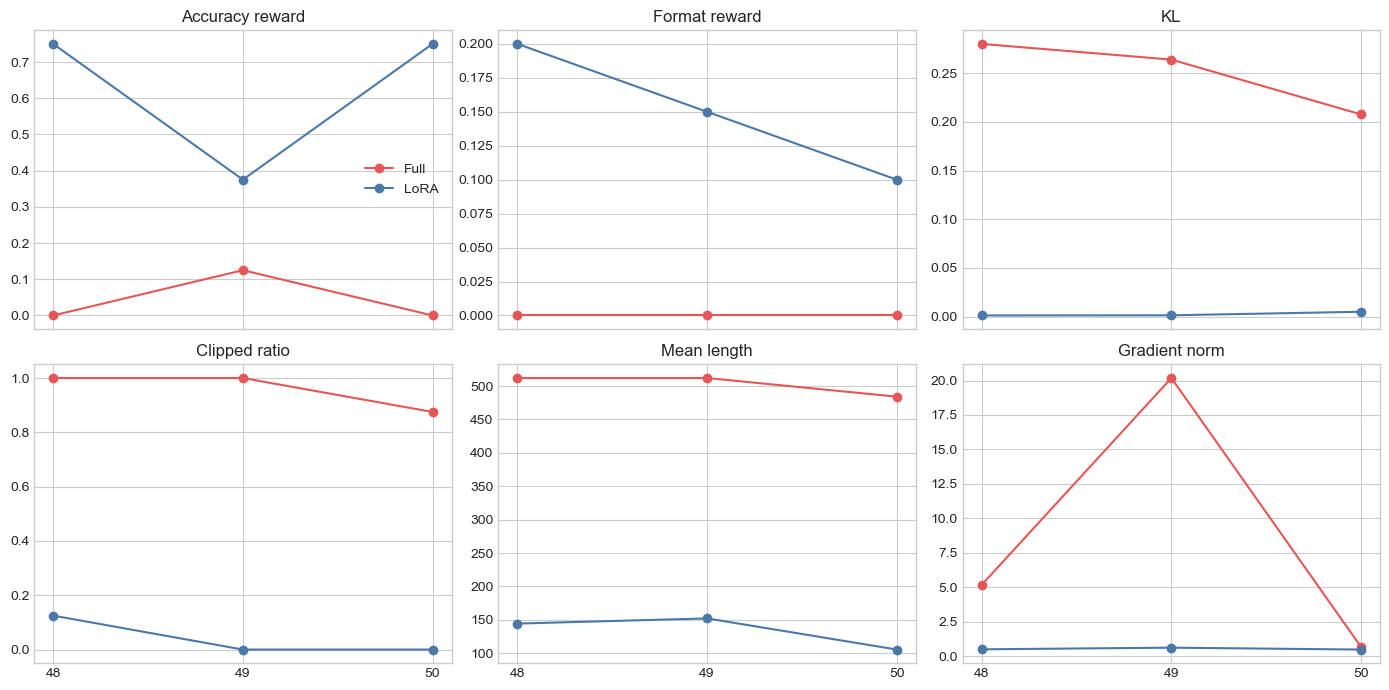

In [10]:
full_tail = pd.DataFrame({
    'step': [48, 49, 50],
    'rewards/accuracy_reward/mean': [0.0, 0.125, 0.0],
    'rewards/format_reward/mean': [0.0, 0.0, 0.0],
    'kl': [0.2800, 0.2639, 0.2076],
    'completions/clipped_ratio': [1.0, 1.0, 0.875],
    'completions/mean_length': [512.0, 512.0, 484.1],
    'grad_norm': [5.181, 20.18, 0.6843],
})
lora_tail = lora_log[lora_log['step'].isin([48, 49, 50])].copy()

compare_series = [
    ('rewards/accuracy_reward/mean', 'Accuracy reward'),
    ('rewards/format_reward/mean', 'Format reward'),
    ('kl', 'KL'),
    ('completions/clipped_ratio', 'Clipped ratio'),
    ('completions/mean_length', 'Mean length'),
    ('grad_norm', 'Gradient norm'),
]

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for ax, (column, title) in zip(axes.flat, compare_series):
    ax.plot(full_tail['step'], full_tail[column], marker='o', color='#E45756', label='Full')
    ax.plot(lora_tail['step'], lora_tail[column], marker='o', color='#4C78A8', label='LoRA')
    ax.set_title(title)
    ax.set_xticks([48, 49, 50])
axes[0, 0].legend()
fig.tight_layout()
save(fig, 'full_lora_step_50')
plt.show()

## Endpoint comparison

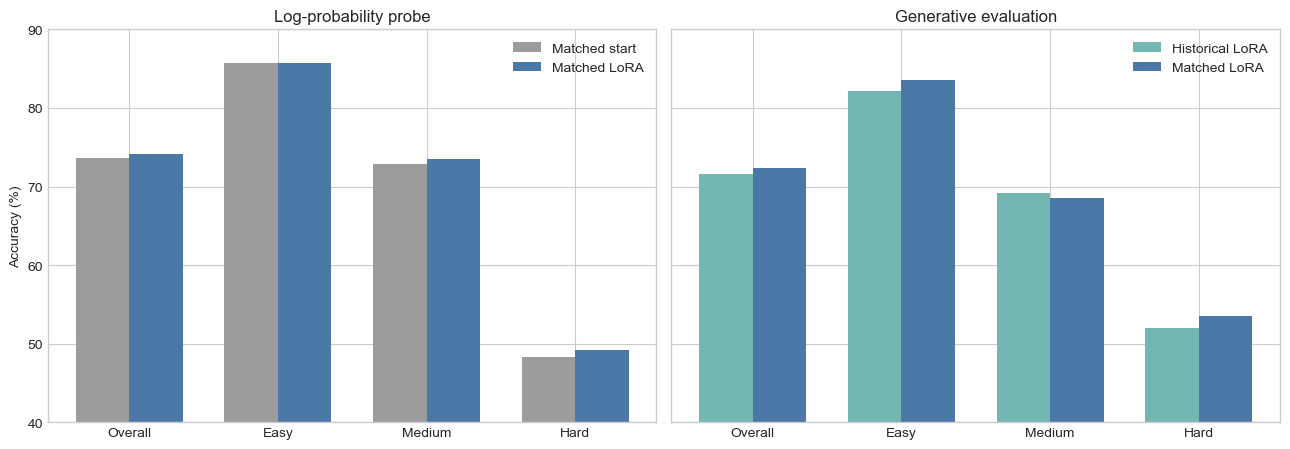

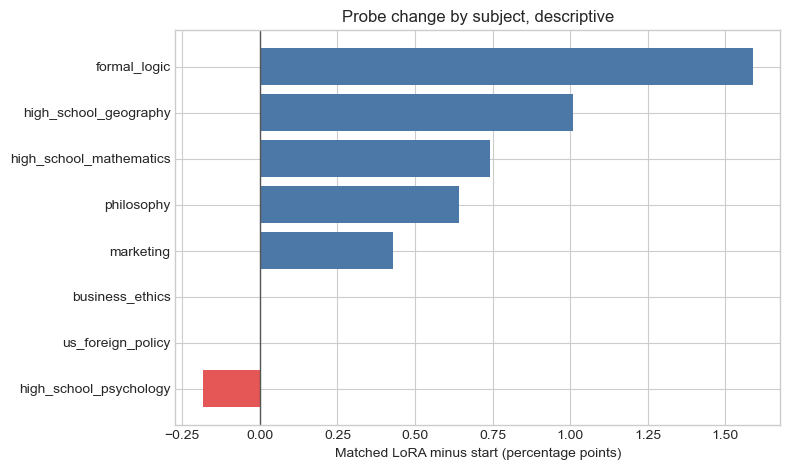

In [11]:
groups = ['Overall', 'Easy', 'Medium', 'Hard']
x = np.arange(len(groups))
width = 0.36

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
axes[0].bar(x - width / 2, np.array(grouped_accuracy(start_probe)) * 100, width, label='Matched start', color='#9C9C9C')
axes[0].bar(x + width / 2, np.array(grouped_accuracy(lora_probe)) * 100, width, label='Matched LoRA', color='#4C78A8')
axes[0].set_title('Log-probability probe')
axes[0].set_xticks(x, groups)
axes[0].set_ylabel('Accuracy (%)')
axes[0].legend()

axes[1].bar(x - width / 2, np.array(grouped_accuracy(hist_eval)) * 100, width, label='Historical LoRA', color='#72B7B2')
axes[1].bar(x + width / 2, np.array(grouped_accuracy(lora_eval)) * 100, width, label='Matched LoRA', color='#4C78A8')
axes[1].set_title('Generative evaluation')
axes[1].set_xticks(x, groups)
axes[1].legend()

for ax in axes:
    ax.set_ylim(40, 90)
fig.tight_layout()
save(fig, 'endpoint_tiers')
plt.show()

subjects = list(start_probe['per_subject_acc'])
subject_delta = pd.Series({
    subject: 100 * (lora_probe['per_subject_acc'][subject] - start_probe['per_subject_acc'][subject])
    for subject in subjects
}).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(subject_delta.index, subject_delta.values, color=np.where(subject_delta.values >= 0, '#4C78A8', '#E45756'))
ax.axvline(0, color='#555555', linewidth=1)
ax.set_xlabel('Matched LoRA minus start (percentage points)')
ax.set_title('Probe change by subject, descriptive')
fig.tight_layout()
save(fig, 'probe_subject_changes')
plt.show()

## Exact values

In [12]:
def paired_stats(rows_a, rows_b):
    rows_a, rows_b = align_pred_rows(rows_a, rows_b)
    correct_a = np.array([row['correct'] for row in rows_a], dtype=bool)
    correct_b = np.array([row['correct'] for row in rows_b], dtype=bool)
    n01 = int(np.sum(~correct_a & correct_b))
    n10 = int(np.sum(correct_a & ~correct_b))
    delta, lo, hi = paired_delta_ci(correct_a, correct_b, n_boot=10000, seed=35)
    return {
        'delta_pp': 100 * delta,
        'ci_low_pp': 100 * lo,
        'ci_high_pp': 100 * hi,
        'gains': n01,
        'losses': n10,
        'mcnemar_p': mcnemar_exact(n01, n10),
    }

endpoint_table = pd.DataFrame([
    {'result': 'Matched start probe', 'overall_acc': 100 * start_probe['overall'], 'format_rate': np.nan},
    {'result': 'Matched LoRA probe', 'overall_acc': 100 * lora_probe['overall'], 'format_rate': np.nan},
    {'result': 'Historical LoRA probe', 'overall_acc': 100 * hist_probe['overall'], 'format_rate': np.nan},
    {'result': 'Matched LoRA generative', 'overall_acc': 100 * lora_eval['overall'], 'format_rate': 100 * lora_eval['format_compliance']},
    {'result': 'Historical LoRA generative', 'overall_acc': 100 * hist_eval['overall'], 'format_rate': 100 * hist_eval['format_compliance']},
])

paired_table = pd.DataFrame([
    {'comparison': 'Start probe to matched LoRA probe', **paired_stats(start_probe_rows, lora_probe_rows)},
    {'comparison': 'Historical to matched LoRA generative', **paired_stats(hist_eval_rows, lora_eval_rows)},
])

display(endpoint_table.round(3))
display(paired_table.round(4))
display(outcomes.round({'peak_reserved_gib': 2, 'wall_minutes': 1}))

,result,overall_acc,format_rate
0,Matched start probe,73.673,NaN
1,Matched LoRA probe,74.098,NaN
2,Historical LoRA probe,74.098,NaN
3,Matched LoRA generative,72.399,94.586
4,Historical LoRA generative,71.603,96.444


,comparison,delta_pp,ci_low_pp,ci_high_pp,gains,losses,mcnemar_p
0,Start probe to matched LoRA probe,0.4246,-0.0531,0.9023,15,7,0.1338
1,Historical to matched LoRA generative,0.7962,-0.5308,2.1231,88,73,0.2698


,run,outcome,updates,peak_reserved_gib,wall_minutes
0,pilot A,OOM,0,78.72,3.2
1,pilot B,OOM,0,78.70,1.7
2,pilot C,passed,30,72.20,13.6
3,pilot A_GC,passed,30,67.22,8.9
4,full A_GC,A1 stop,50,67.21,23.7
5,LoRA A_GC,completed,500,24.12,213.7


## Cross-referenced conclusion

Gradient checkpointing made the 3B full parameter arm fit in memory. But it reached registered A1 truncation stop at step 50 and produced no endpoint. The matched LoRA arm completed all 500 steps with much lower memory and reproduced the historical seed 0 endpoint within 0.8 points. Its probe changed by only 0.42 points from the matched start, below the study's 2-point materiality rule. So, experiment 035 supports a stability role for LoRA under this recipe, but it doesn't complete a full-vs-LoRA endpoint comparison or show that LoRA is better.